# 48 — Binary Refined Eel and Grouper Optimizer (K-means sampling) (BmEGO) for feature selection

Continuous algorithm: *Kyrou G. et al. (2024). Refining the eel and grouper optimizer with intelligent modifications. Computation.*  
Binarised with the **Unified Binarization Framework (UBF)**: deterministic sign mapping, density-diverse initial population, fitness memoisation and elite bit-flip local search. RS = random-search control under the same framework. Protocol: see `00_data_and_protocol`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from fsbench import experiment as ex, plots
pd.set_option("display.width", 200, "display.max_columns", 40)

In [2]:
METHOD = "mEGO"
recs = ex.run_method(METHOD)
base = {m: ex.run_method(m) for m in ("ANOVA", "Chi2", "AllFeatures", "RS")}
df = ex.flatten(recs)
print(len(recs), "runs")

80 runs


## Performance on the test split (mean ± std over 10 runs)

In [3]:
plots.summary_table(df, by=("dataset", "classifier"))

,dataset,classifier,accuracy,precision_macro,recall_macro,f1_macro,auc_macro,n_selected,search_time_s
0,dermatology,ANN,0.9691 ± 0.0137,0.9692 ± 0.0138,0.9666 ± 0.014,0.9672 ± 0.0135,0.9983 ± 0.0011,18.6 ± 1.5776,19.6295 ± 3.9239
1,dermatology,DT,0.9455 ± 0.0235,0.9387 ± 0.0251,0.9335 ± 0.0267,0.9346 ± 0.0261,0.9613 ± 0.0156,18.6 ± 1.5776,19.6295 ± 3.9239
2,dermatology,KNN,0.9545 ± 0.0177,0.9491 ± 0.0235,0.9533 ± 0.0156,0.9497 ± 0.0211,0.9946 ± 0.0048,18.6 ± 1.5776,19.6295 ± 3.9239
3,dermatology,RF,0.9691 ± 0.0115,0.9673 ± 0.0117,0.9651 ± 0.0114,0.9658 ± 0.0116,0.9981 ± 0.0009,18.6 ± 1.5776,19.6295 ± 3.9239
4,dermatology,SVM,0.9609 ± 0.0161,0.9597 ± 0.0165,0.9579 ± 0.0158,0.958 ± 0.0162,0.9976 ± 0.0014,18.6 ± 1.5776,19.6295 ± 3.9239
5,dermatology,XGB,0.9536 ± 0.0184,0.9519 ± 0.0193,0.9453 ± 0.0231,0.9472 ± 0.0211,0.9945 ± 0.0029,18.6 ± 1.5776,19.6295 ± 3.9239
6,ionosphere,ANN,0.8849 ± 0.0273,0.8877 ± 0.025,0.8604 ± 0.0375,0.8701 ± 0.034,0.9238 ± 0.0214,5.9 ± 3.3813,21.2796 ± 0.9542
7,ionosphere,DT,0.8726 ± 0.0289,0.8641 ± 0.0338,0.8584 ± 0.029,0.8608 ± 0.0309,0.8575 ± 0.0286,5.9 ± 3.3813,21.2796 ± 0.9542
8,ionosphere,KNN,0.883 ± 0.0315,0.9014 ± 0.0205,0.8473 ± 0.0453,0.8636 ± 0.041,0.9083 ± 0.026,5.9 ± 3.3813,21.2796 ± 0.9542
9,ionosphere,RF,0.9094 ± 0.0127,0.91 ± 0.0126,0.8917 ± 0.0166,0.8993 ± 0.0148,0.9603 ± 0.02,5.9 ± 3.3813,21.2796 ± 0.9542


## Comparison with the classical filters (F1-macro, averaged over the six classifiers)

In [4]:
allb = pd.concat([df] + [ex.flatten(r) for r in base.values()])
pivot = allb.groupby(["dataset", "method"]).f1_macro.mean().unstack().round(4)
pivot

method,ANOVA,AllFeatures,Chi2,RS,mEGO
dataset,,,,,
dermatology,0.9676,0.9568,0.9568,0.9552,0.9537
ionosphere,0.8734,0.8907,0.8734,0.8765,0.8802
musk1,0.8449,0.8634,0.8603,0.8553,0.8606
sonar,0.8293,0.8317,0.8188,0.7940,0.8079
spectf,0.5448,0.5448,0.5448,0.5471,0.5338
vehicle,0.6656,0.7311,0.6558,0.7273,0.7289
wdbc,0.9294,0.9442,0.9462,0.9291,0.9391
wine,0.9628,0.9524,0.9542,0.9530,0.9556


In [5]:
allb.groupby(["dataset", "method"])[["n_selected", "search_time_s"]].mean().unstack().round(2)

n_selected                                search_time_s                                
method           ANOVA AllFeatures   Chi2    RS  mEGO         ANOVA AllFeatures  Chi2     RS   mEGO
dataset                                                                                            
dermatology       24.0        34.0   34.0  18.1  18.6          0.36         0.0  0.23  13.37  19.63
ionosphere         3.0        33.0    3.0   6.4   5.9          0.33         0.0  0.32  15.02  21.28
musk1             66.0       166.0  133.0  55.9  82.1          0.38         0.0  0.28  21.06  30.00
sonar             24.0        60.0   30.0  21.5  25.2          0.30         0.0  0.28  11.13  23.29
spectf            44.0        44.0   44.0  16.9  28.7          0.31         0.0  0.20  12.17  19.84
vehicle            9.0        18.0    7.0  10.1  12.3          0.46         0.0  0.49  28.40  12.13
wdbc              18.0        30.0   21.0   9.9  14.3          0.37         0.0  0.35  20.84  28.56
wine               9.0        13.0    8.0   5.8   7.2          0.18         0.0  0.19   7.11   3.97

## Convergence: best-so-far fitness per iteration
A flat tail means the search converged within the budget; a still-decreasing tail means more iterations could help.

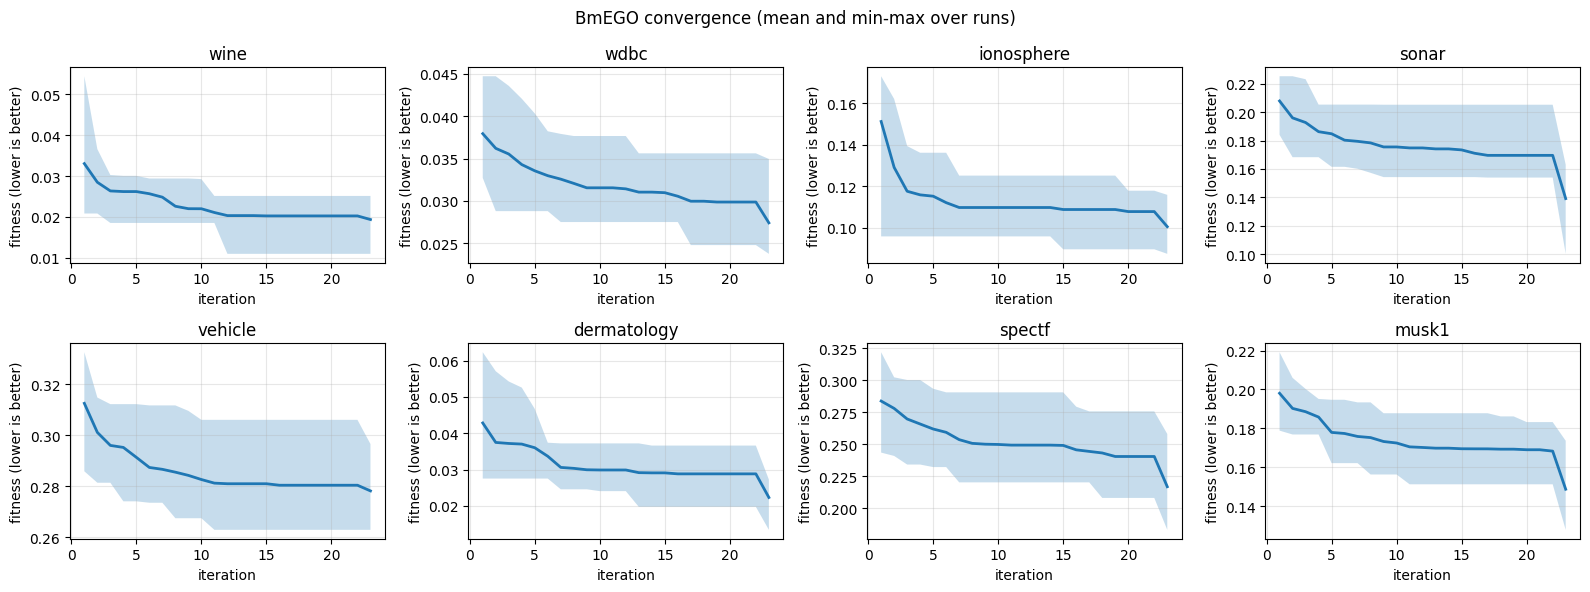

In [6]:
plots.convergence(recs, title="BmEGO convergence (mean and min-max over runs)", name="convergence_mEGO");

## Confusion matrices and ROC curves (run 0, KNN)

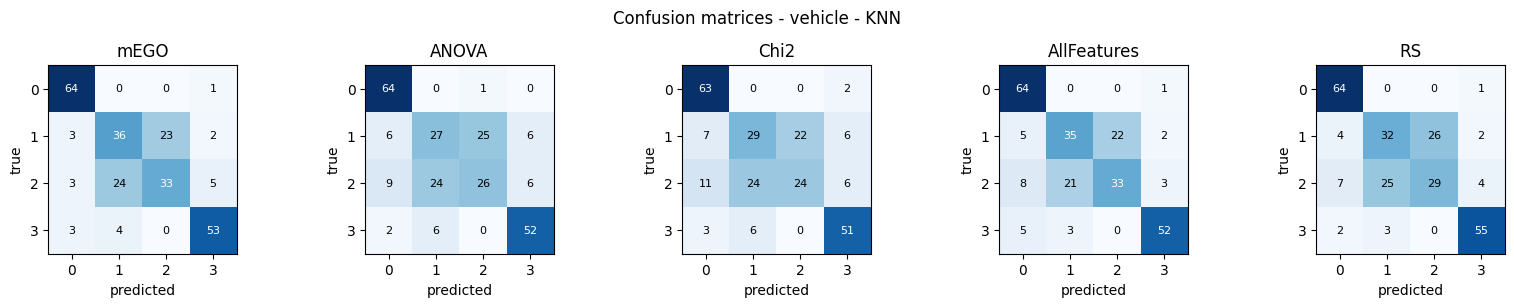

In [7]:
ds = "vehicle"
plots.confusion_matrices({METHOD: recs, **base}, ds, name=f"cm_{METHOD}_{ds}");

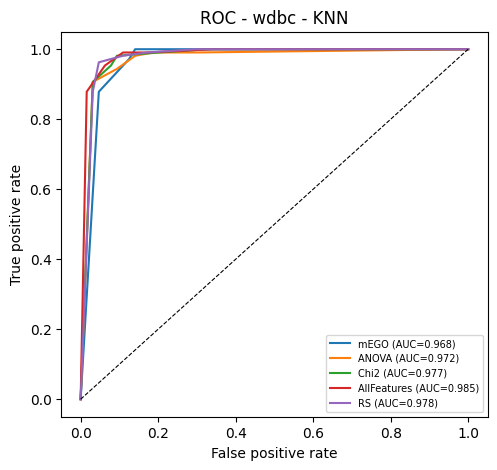

In [8]:
plots.roc_curves({METHOD: recs, **base}, "wdbc", name=f"roc_{METHOD}_wdbc");

## Computation
`n_classifier_fits` counts real classifier trainings; `cache_hits` are FEs served by the memo.

In [9]:
pd.DataFrame([{k: r[k] for k in ("dataset", "run", "n_selected", "time_s", "n_classifier_fits", "cache_hits")} for r in recs]).groupby("dataset").mean().round(2)

,run,n_selected,time_s,n_classifier_fits,cache_hits
dataset,,,,,
dermatology,4.5,18.6,19.63,687.9,312.1
ionosphere,4.5,5.9,21.28,829.5,170.5
musk1,4.5,82.1,30.00,927.2,72.8
sonar,4.5,25.2,23.29,887.5,112.5
spectf,4.5,28.7,19.84,739.5,260.5
vehicle,4.5,12.3,12.13,373.8,626.2
wdbc,4.5,14.3,28.56,764.2,235.8
wine,4.5,7.2,3.97,322.3,677.7
